<a href="https://colab.research.google.com/github/davidlealo/sic_ia_2026/blob/main/ejercicios_profesor/sic2026_ia_clase15_keras_aplicado_PROFE_DESAFIO_NOexitoso.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

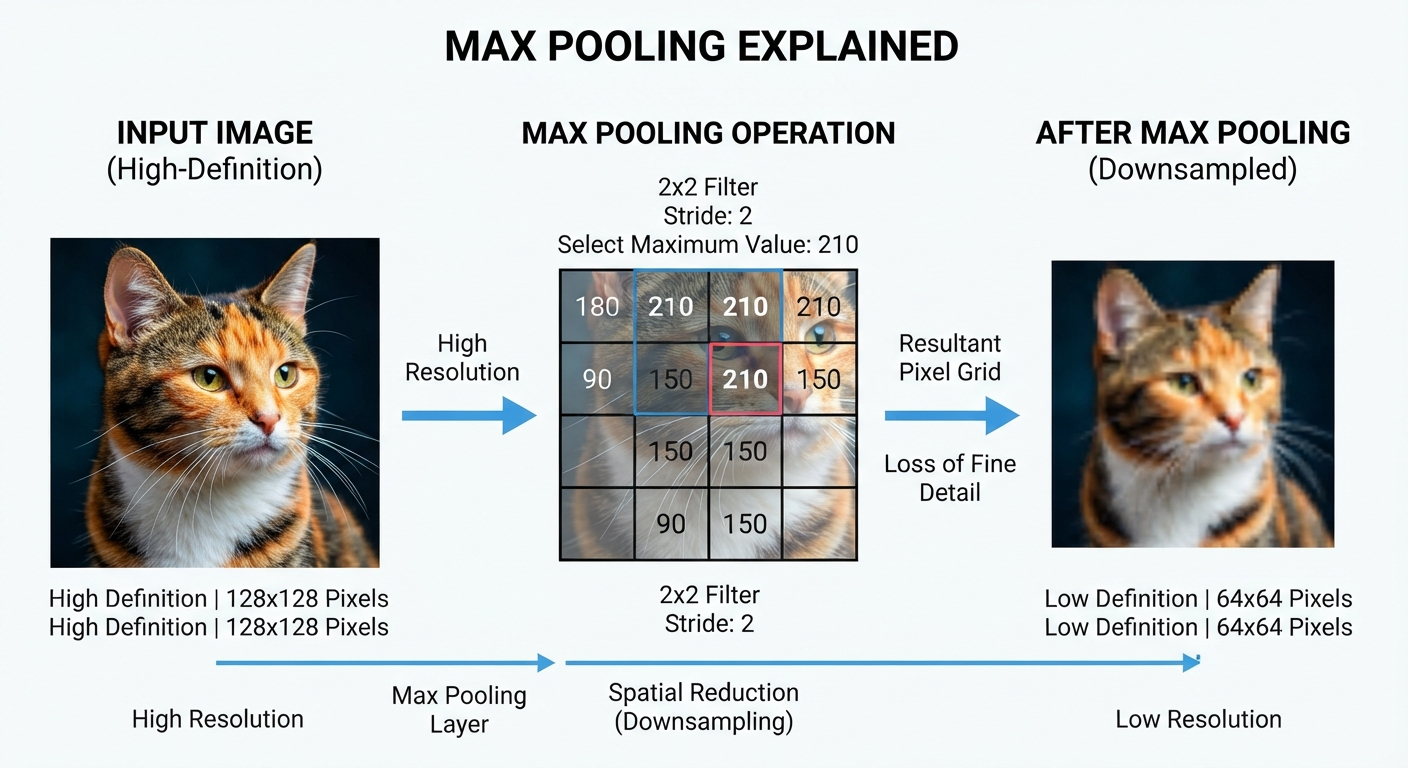

# SIC 2026 · Inteligencia Artificial
## Clase 15: Keras aplicado, con casos reales (Capítulo 8, Unidad 3)

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

En la Clase 14 llegamos hasta la lámina 152. Hoy vemos **Keras a fondo**, pero aprendiendo con **casos reales** que ya conocen, para comparar las redes neuronales con lo que hicieron en scikit-learn:

| Hora | Parte | Caso | Tipo de problema |
|---|---|---|---|
| 18:00 a 18:25 | 1. Keras paso a paso | | Los 5 pasos y cómo contar parámetros |
| 18:25 a 19:25 | 2. Fuga de clientes | Telco Customer Churn (Clase 6) | Clasificación binaria desbalanceada |
| 19:25 a 19:35 | Pausa | | |
| 19:35 a 20:15 | 3. Precio de diamantes | Diamonds (Clase 4) | Regresión |
| 20:15 a 20:40 | 4. Gama de precio | Diamonds (Clase 4) | Clasificación multiclase |
| 20:40 a 21:20 | 5. Prendas de ropa | Fashion-MNIST | Imágenes con CNN |
| 21:20 a 21:55 | 6. Pasajeros de avión | Flights | Series de tiempo con RNN, LSTM y GRU |
| Para la casa | 7. Desafío | Telco Customer Churn | Superar al mejor modelo |

**Hay muchos ejercicios (16 más el desafío).** La idea es que ustedes escriban el código. Cada ejercicio tiene su verificación y las soluciones están al final.

**Antes de empezar:** *Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU (T4)*.

In [9]:
!pip install -q kagglehub

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import (roc_auc_score, recall_score, precision_score, f1_score,
                             accuracy_score, mean_absolute_error, classification_report, confusion_matrix)

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

def graficar(historia, metricas=("loss",)):
    fig, ejes = plt.subplots(1, len(metricas), figsize=(5.5 * len(metricas), 3.5))
    ejes = np.atleast_1d(ejes)
    for ax, m in zip(ejes, metricas):
        ax.plot(historia.history[m], label="entrenamiento")
        if "val_" + m in historia.history:
            ax.plot(historia.history["val_" + m], label="validación")
        ax.set_title(m); ax.set_xlabel("Época"); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "no")

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
import keras
from keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# ==========================================
# PASO 1: Cargar y preparar los datos
# ==========================================
print("--- PASO 1: Cargando y preparando el dataset Iris ---")
iris = load_iris()
X, y = iris.data, iris.target

# Dividimos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Escalamos las características para ayudar a la convergencia de la red neuronal
escaler = StandardScaler()
X_train_scaled = escaler.fit_transform(X_train)
X_test_scaled = escaler.transform(X_test)

print(f"Tamaño de entrenamiento: {X_train_scaled.shape}")
print(f"Tamaño de prueba: {X_test_scaled.shape}")
print(f"Clases de flores a clasificar: {iris.target_names}\n")

--- PASO 1: Cargando y preparando el dataset Iris ---
Tamaño de entrenamiento: (120, 4)
Tamaño de prueba: (30, 4)
Clases de flores a clasificar: ['setosa' 'versicolor' 'virginica']



In [ ]:
# ==========================================
# PASO 2: Definir la arquitectura de la red
# ==========================================
print("--- PASO 2: Definiendo la arquitectura de la Red Neuronal ---")
keras.utils.set_random_seed(42)

# Creamos una red neuronal secuencial sencilla
modelo_iris = keras.Sequential([
    # Capa de entrada que coincide con las 4 características físicas del Iris
    layers.Input(shape=(4,)),
    # Capa oculta con 8 neuronas y función de activación ReLU
    layers.Dense(8, activation="relu"),
    # Capa de salida con 3 neuronas (una por clase) y activación Softmax para probabilidades
    layers.Dense(3, activation="softmax")
])

modelo_iris.summary()
print()

--- PASO 2: Definiendo la arquitectura de la Red Neuronal ---


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# PASO 3: Compilar el modelo
# ==========================================
print("--- PASO 3: Compilando el modelo ---")
# Usamos sparse_categorical_crossentropy porque las etiquetas de clase son números enteros (0, 1, 2)
modelo_iris.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Modelo compilado listo para entrenar.\n")

--- PASO 3: Compilando el modelo ---
Modelo compilado listo para entrenar.



In [ ]:
# ==========================================
# PASO 4: Entrenar el modelo
# ==========================================
print("--- PASO 4: Entrenando el modelo ---")
history = modelo_iris.fit(
    X_train_scaled, y_train,
    validation_split=0.15,
    epochs=120,
    batch_size=16,
    verbose=1 # CON 0 se Ocultamos los logs detallados por época para enfocarnos en los resultados finales
    # Con 1 podemos ver los logs
)
print(f"¡Entrenamiento completado! Épocas ejecutadas: {len(history.history['loss'])}\n")

--- PASO 4: Entrenando el modelo ---
Epoch 1/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 368ms/step - accuracy: 0.5980 - loss: 0.8625 - val_accuracy: 0.6667 - val_loss: 0.8720
Epoch 2/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6471 - loss: 0.8414 - val_accuracy: 0.6667 - val_loss: 0.8551
Epoch 3/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.6961 - loss: 0.8213 - val_accuracy: 0.6667 - val_loss: 0.8385
Epoch 4/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.7255 - loss: 0.8017 - val_accuracy: 0.6667 - val_loss: 0.8222
Epoch 5/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7255 - loss: 0.7824 - val_accuracy: 0.6111 - val_loss: 0.8060
Epoch 6/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.7157 - loss: 0.7637 - val_accuracy: 0.6111 - val_loss: 0.7903
Epoch 7/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7255 - loss: 0.7457 - val_accuracy: 0.6111 - val_loss: 0.7752
Epoch 8/120
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7451 - loss: 0.7

=== PROCESO DE APRENDIZAJE POR ÉPOCA (Muestra cada 20 épocas) ===

Época 001 | Pérdida Train: 0.8625 - Val: 0.8720 | Exactitud Train: 59.80% - Val: 66.67%
Época 021 | Pérdida Train: 0.5516 - Val: 0.6259 | Exactitud Train: 80.39% - Val: 61.11%
Época 041 | Pérdida Train: 0.4307 - Val: 0.5323 | Exactitud Train: 83.33% - Val: 72.22%
Época 061 | Pérdida Train: 0.3673 - Val: 0.4705 | Exactitud Train: 85.29% - Val: 72.22%
Época 081 | Pérdida Train: 0.3245 - Val: 0.4263 | Exactitud Train: 86.27% - Val: 77.78%
Época 101 | Pérdida Train: 0.2847 - Val: 0.3799 | Exactitud Train: 87.25% - Val: 83.33%

Época Final (120) | Pérdida Train: 0.2424 - Val: 0.3070 | Exactitud Train: 91.18% - Val: 88.89%

Graficando curvas de aprendizaje...


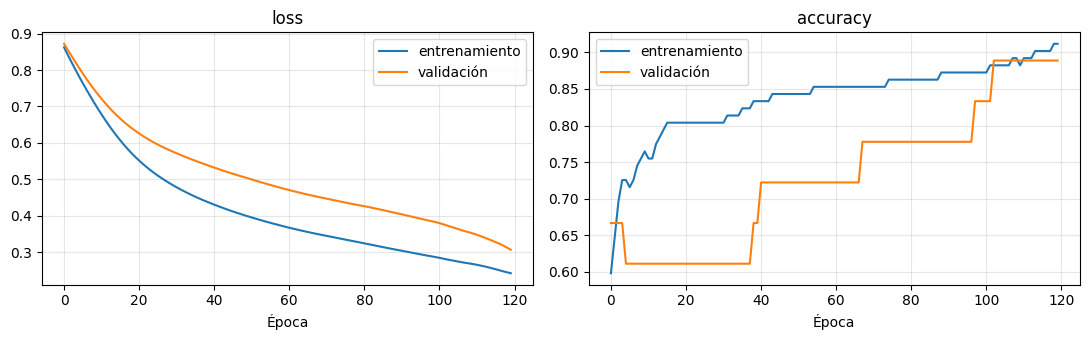

In [ ]:
print("=== PROCESO DE APRENDIZAJE POR ÉPOCA (Muestra cada 20 épocas) ===\n")

# Mostramos los valores numéricos del historial de entrenamiento cada 20 épocas
for epoca in range(0, len(history.history['loss']), 20):
    loss_train = history.history['loss'][epoca]
    val_loss = history.history['val_loss'][epoca]
    acc_train = history.history['accuracy'][epoca]
    val_acc = history.history['val_accuracy'][epoca]

    print(f"Época {epoca+1:03d} | Pérdida Train: {loss_train:.4f} - Val: {val_loss:.4f} | Exactitud Train: {acc_train*100:.2f}% - Val: {val_acc*100:.2f}%")

# Mostramos el resultado de la última época
ultima_epoca = len(history.history['loss']) - 1
print(f"\nÉpoca Final ({ultima_epoca+1:03d}) | Pérdida Train: {history.history['loss'][ultima_epoca]:.4f} - Val: {history.history['val_loss'][ultima_epoca]:.4f} | Exactitud Train: {history.history['accuracy'][ultima_epoca]*100:.2f}% - Val: {history.history['val_accuracy'][ultima_epoca]*100:.2f}%")

print("\nGraficando curvas de aprendizaje...")
graficar(history, metricas=("loss", "accuracy"))

In [ ]:
# El modelo nos entrega la probabilidad final (activación Softmax)
probabilidades = modelo_iris.predict(flor_ejemplo, verbose=1)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step


In [ ]:
print("\n2. PROCESAMIENTO DE UNA SOLA FLOR (Clase Real:", nombre_real.upper(), "):")
print(f"Características escaladas de entrada: {flor_ejemplo[0]}")
print("Salida de la capa Softmax (Probabilidades por clase):")


2. PROCESAMIENTO DE UNA SOLA FLOR (Clase Real: SETOSA ):
Características escaladas de entrada: [-1.72156775 -0.10821272 -1.40250384 -1.32327558]
Salida de la capa Softmax (Probabilidades por clase):


In [ ]:
for i, nombre_clase in enumerate(iris.target_names):
    print(f"  - Probabilidad para '{nombre_clase}': {probabilidades[i] * 100:.2f}%")

  - Probabilidad para 'setosa': 98.82%
  - Probabilidad para 'versicolor': 1.17%
  - Probabilidad para 'virginica': 0.01%


In [ ]:
prediccion_final = probabilidades.argmax()
print(f"Predicción final del modelo: {iris.target_names[prediccion_final].upper()}")

Predicción final del modelo: SETOSA


In [ ]:
# ==========================================
# PASO 5: Evaluar y mostrar los resultados detallados
# ==========================================
print("--- PASO 5: Evaluación y Resultados Detallados ---")

# 5.1 Pérdida y exactitud en el conjunto de prueba independiente
loss, accuracy = modelo_iris.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Pérdida (Loss) en Prueba: {loss:.4f}")
print(f"Exactitud (Accuracy) en Prueba: {accuracy * 100:.2f}%\n")

# 5.2 Obtener predicciones del modelo
predicciones_prob = modelo_iris.predict(X_test_scaled, verbose=0)
# Tomamos la clase con mayor probabilidad (argmax)
predicciones_clase = predicciones_prob.argmax(axis=1)

# 5.3 Reporte detallado de clasificación por clase
print("Reporte de Clasificación por clase de flor:")
print(classification_report(y_test, predicciones_clase, target_names=iris.target_names))

# 5.4 Matriz de Confusión
print("Matriz de Confusión:")
print(confusion_matrix(y_test, predicciones_clase))
print("\n(Las filas indican la clase real; las columnas representan la predicción de la red)")

--- PASO 5: Evaluación y Resultados Detallados ---
Pérdida (Loss) en Prueba: 0.3286
Exactitud (Accuracy) en Prueba: 83.33%

Reporte de Clasificación por clase de flor:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.50      0.67        10
   virginica       0.67      1.00      0.80        10

    accuracy                           0.83        30
   macro avg       0.89      0.83      0.82        30
weighted avg       0.89      0.83      0.82        30

Matriz de Confusión:
[[10  0  0]
 [ 0  5  5]
 [ 0  0 10]]

(Las filas indican la clase real; las columnas representan la predicción de la red)


In [ ]:
# 5.5 Ejemplo visual de predicciones reales versus predicciones del modelo
print("\nEjemplos de predicción para los primeros 5 elementos de prueba:")
for i in range(5):
    real = iris.target_names[y_test[i]]
    pred = iris.target_names[predicciones_clase[i]]
    probs = [f"{p*100:.1f}%" for p in predicciones_prob[i]]
    print(f"Caso {i+1}: Real: {real.ljust(12)} | Predicción: {pred.ljust(12)} | Probabilidades: {probs}")



Ejemplos de predicción para los primeros 5 elementos de prueba:
Caso 1: Real: setosa       | Predicción: setosa       | Probabilidades: ['98.8%', '1.2%', '0.0%']
Caso 2: Real: virginica    | Predicción: virginica    | Probabilidades: ['0.6%', '26.7%', '72.8%']
Caso 3: Real: versicolor   | Predicción: versicolor   | Probabilidades: ['13.3%', '85.0%', '1.7%']
Caso 4: Real: versicolor   | Predicción: versicolor   | Probabilidades: ['6.9%', '91.8%', '1.3%']
Caso 5: Real: setosa       | Predicción: setosa       | Probabilidades: ['99.4%', '0.6%', '0.0%']


### 💡 Abriendo la "Caja Negra": ¿Qué podemos imprimir para los estudiantes?

Para ayudar a que los estudiantes visualicen que la red neuronal no es magia, sino un conjunto de operaciones matemáticas y optimización, podemos imprimir e inspeccionar varios elementos en vivo:

#### 1. Inspeccionar los Pesos y Sesgos Iniciales (Azar)
Antes de entrenar, la red se inicializa con valores aleatorios. Podemos mostrar cómo se ven físicamente los pesos ($W$) y sesgos ($b$) de una neurona específica:
```python
# Obtener los pesos de la primera capa oculta (Dense)
pesos, sesgos = modelo_iris.layers[0].get_weights()
print("Matriz de pesos de la entrada a la capa oculta (4 entradas x 8 neuronas):\n", pesos)
print("\nSesgos (biases) de las 8 neuronas de la capa oculta:\n", sesgos)
```

#### 2. Ver la Transformación de una Entrada a Probabilidades (Softmax)
Podemos tomar una sola flor de prueba, pasarla por el modelo y mostrar el vector numérico crudo (llamado *logits*) y cómo la función **Softmax** lo convierte en una distribución de probabilidad que suma exactamente 100%:
```python
una_flor = X_test_scaled[0:1]
logits = modelo_iris.predict(una_flor, verbose=0)
print(f"Logits crudos de salida: {logits[0]}")
print(f"Suma de probabilidades: {np.sum(logits[0]) * 100:.1f}%")
```

#### 3. El Progreso de Pérdida (Loss) y Métricas por Época
Podemos graficar o imprimir el diccionario `history.history` para mostrar cómo la pérdida disminuye paso a paso mientras la exactitud aumenta. Esto demuestra que la red está 'aprendiendo' al ajustar esos pesos aleatorios del paso 1 utilizando el gradiente descendente.

In [ ]:
import numpy as np

print("=== DEMOSTRACIÓN DIDÁCTICA PARA ESTUDIANTES ===\n")

# 1. Inspeccionar Pesos y Sesgos Finales (Post-entrenamiento)
pesos, sesgos = modelo_iris.layers[0].get_weights()
print("1. PESOS Y SESGOS APRENDIDOS (Capa Oculta 1):")
print(f"Forma de la matriz de pesos (W): {pesos.shape} (4 entradas x 8 neuronas)")
print("Pesos de la neurona #1 para las 4 entradas:", pesos[:, 0])
print("Sesgo (bias) de la neurona #1:", sesgos[0])
print("-" * 60)

=== DEMOSTRACIÓN DIDÁCTICA PARA ESTUDIANTES ===

1. PESOS Y SESGOS APRENDIDOS (Capa Oculta 1):
Forma de la matriz de pesos (W): (4, 8) (4 entradas x 8 neuronas)
Pesos de la neurona #1 para las 4 entradas: [ 0.35409692  0.19567174 -0.7597741   0.64461803]
Sesgo (bias) de la neurona #1: -0.06765914
------------------------------------------------------------


In [ ]:
# 2. Ver la transformación de Softmax paso a paso en un caso real
# Tomamos la primera flor de prueba (índice 0)
flor_ejemplo = X_test_scaled[0:1]
clase_real_idx = y_test[0]
nombre_real = iris.target_names[clase_real_idx]
nombre_real

np.str_('setosa')

In [ ]:
# El modelo nos entrega la probabilidad final (activación Softmax)
probabilidades = modelo_iris.predict(flor_ejemplo, verbose=1)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step


In [ ]:
print("\n2. PROCESAMIENTO DE UNA SOLA FLOR (Clase Real:", nombre_real.upper(), "):")
print(f"Características escaladas de entrada: {flor_ejemplo[0]}")
print("Salida de la capa Softmax (Probabilidades por clase):")


2. PROCESAMIENTO DE UNA SOLA FLOR (Clase Real: SETOSA ):
Características escaladas de entrada: [-1.72156775 -0.10821272 -1.40250384 -1.32327558]
Salida de la capa Softmax (Probabilidades por clase):


In [ ]:
for i, nombre_clase in enumerate(iris.target_names):
    print(f"  - Probabilidad para '{nombre_clase}': {probabilidades[i] * 100:.2f}%")

  - Probabilidad para 'setosa': 98.82%
  - Probabilidad para 'versicolor': 1.17%
  - Probabilidad para 'virginica': 0.01%


In [ ]:
prediccion_final = probabilidades.argmax()
print(f"Predicción final del modelo: {iris.target_names[prediccion_final].upper()}")

Predicción final del modelo: SETOSA


In [ ]:
import seaborn as sns

# importar datasets de IRIS de Seaborn
dataset = sns.load_dataset('iris')

In [ ]:
dataset

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [ ]:
dataset.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
# Escalar con StandarScaler los valores de X
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

from sklearn.preprocessing import StandardScaler

escaler = StandardScaler()
X_scaled = escaler.fit_transform(X)

In [ ]:
# convertir C_scaled a dataframe para hacer el describe
df_scaled = pd.DataFrame(X_scaled, columns=dataset.columns[:-1])
df_scaled.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,1.500000e+02,1.500000e+02,1.500000e+02,1.500000e+02
mean,-4.736952e-16,-7.815970e-16,-4.263256e-16,-4.736952e-16
std,1.003350e+00,1.003350e+00,1.003350e+00,1.003350e+00
min,-1.870024e+00,-2.433947e+00,-1.567576e+00,-1.447076e+00
25%,-9.006812e-01,-5.923730e-01,-1.226552e+00,-1.183812e+00
50%,-5.250608e-02,-1.319795e-01,3.364776e-01,1.325097e-01
75%,6.745011e-01,5.586108e-01,7.627583e-01,7.906707e-01
max,2.492019e+00,3.090775e+00,1.785832e+00,1.712096e+00


In [ ]:
# Si a X le hciieramos MinMaxScaler
from sklearn.preprocessing import MinMaxScaler

escaler = MinMaxScaler()
X_scaled = escaler.fit_transform(X)

In [ ]:
# Convertir X_scaled a dataframe para hacer el describe
df_scaled = pd.DataFrame(X_scaled, columns=dataset.columns[:-1])
df_scaled.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,0.428704,0.440556,0.467458,0.458056
std,0.230018,0.181611,0.299203,0.317599
min,0.000000,0.000000,0.000000,0.000000
25%,0.222222,0.333333,0.101695,0.083333
50%,0.416667,0.416667,0.567797,0.500000
75%,0.583333,0.541667,0.694915,0.708333
max,1.000000,1.000000,1.000000,1.000000


In [ ]:
# Dividir y y X_scaled en train y test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [ ]:
# ==========================================
# PASO 4: Entrenar el modelo
# ==========================================
print("--- PASO 4: Entrenando el modelo ---")

# Mapeamos las etiquetas de texto a índices numéricos (0, 1, 2)
mapeo_clases = {clase: idx for idx, clase in enumerate(dataset['species'].unique())}
y_train_numeric = np.array([mapeo_clases[val] for val in y_train])
y_test_numeric = np.array([mapeo_clases[val] for val in y_test])

history = modelo_iris.fit(
    X_train, y_train_numeric,
    validation_split=0.15,
    epochs=120,
    batch_size=16,
    verbose=0 # Ocultamos los logs detallados por época para enfocarnos en los resultados finales
)
print(f"¡Entrenamiento completado! Épocas ejecutadas: {len(history.history['loss'])}\n")

--- PASO 4: Entrenando el modelo ---
¡Entrenamiento completado! Épocas ejecutadas: 120



=== PROCESO DE APRENDIZAJE POR ÉPOCA (Muestra cada 20 épocas) ===

Época 001 | Pérdida Train: 0.8711 - Val: 0.7780 | Exactitud Train: 35.29% - Val: 55.56%
Época 021 | Pérdida Train: 0.4109 - Val: 0.4820 | Exactitud Train: 94.12% - Val: 88.89%
Época 041 | Pérdida Train: 0.3536 - Val: 0.4382 | Exactitud Train: 95.10% - Val: 88.89%
Época 061 | Pérdida Train: 0.3121 - Val: 0.4059 | Exactitud Train: 96.08% - Val: 94.44%
Época 081 | Pérdida Train: 0.2795 - Val: 0.3777 | Exactitud Train: 95.10% - Val: 94.44%
Época 101 | Pérdida Train: 0.2523 - Val: 0.3528 | Exactitud Train: 96.08% - Val: 94.44%

Época Final (120) | Pérdida Train: 0.2304 - Val: 0.3321 | Exactitud Train: 96.08% - Val: 94.44%

Graficando curvas de aprendizaje...


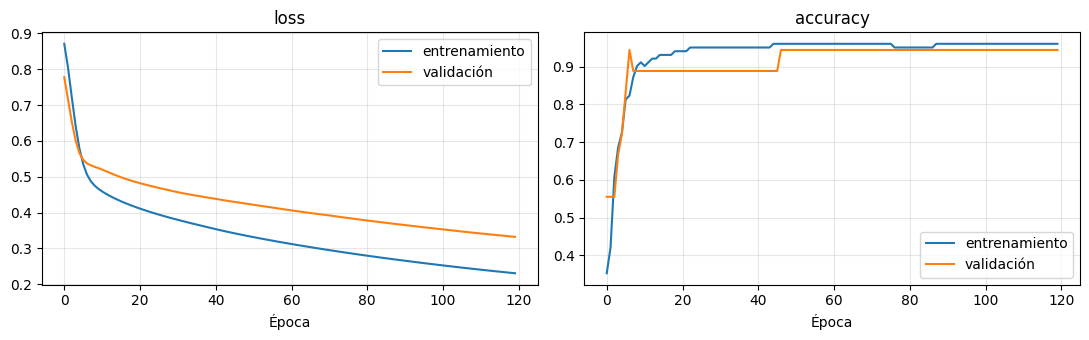

In [ ]:
print("=== PROCESO DE APRENDIZAJE POR ÉPOCA (Muestra cada 20 épocas) ===\n")

# Mostramos los valores numéricos del historial de entrenamiento cada 20 épocas
for epoca in range(0, len(history.history['loss']), 20):
    loss_train = history.history['loss'][epoca]
    val_loss = history.history['val_loss'][epoca]
    acc_train = history.history['accuracy'][epoca]
    val_acc = history.history['val_accuracy'][epoca]

    print(f"Época {epoca+1:03d} | Pérdida Train: {loss_train:.4f} - Val: {val_loss:.4f} | Exactitud Train: {acc_train*100:.2f}% - Val: {val_acc*100:.2f}%")

# Mostramos el resultado de la última época
ultima_epoca = len(history.history['loss']) - 1
print(f"\nÉpoca Final ({ultima_epoca+1:03d}) | Pérdida Train: {history.history['loss'][ultima_epoca]:.4f} - Val: {history.history['val_loss'][ultima_epoca]:.4f} | Exactitud Train: {history.history['accuracy'][ultima_epoca]*100:.2f}% - Val: {history.history['val_accuracy'][ultima_epoca]*100:.2f}%")

print("\nGraficando curvas de aprendizaje...")
graficar(history, metricas=("loss", "accuracy"))

In [ ]:
# 2. Ver la transformación de Softmax paso a paso en un caso real
# Tomamos la primera flor de prueba (índice 0)
flor_ejemplo = X_test[0:1]
clase_real_idx = y_test_numeric[0] # Usamos la versión numérica para indexar los nombres originales
nombre_real = iris.target_names[clase_real_idx]
nombre_real

np.str_('versicolor')

In [ ]:
# El modelo nos entrega la probabilidad final (activación Softmax)
probabilidades = modelo_iris.predict(flor_ejemplo, verbose=1)[0]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


In [ ]:
print("\n2. PROCESAMIENTO DE UNA SOLA FLOR (Clase Real:", nombre_real.upper(), "):")
print(f"Características escaladas de entrada: {flor_ejemplo[0]}")
print("Salida de la capa Softmax (Probabilidades por clase):")


2. PROCESAMIENTO DE UNA SOLA FLOR (Clase Real: VERSICOLOR ):
Características escaladas de entrada: [0.5        0.33333333 0.62711864 0.45833333]
Salida de la capa Softmax (Probabilidades por clase):


In [ ]:
# Agrupar por especie y mostrar los estadísticos descriptivos (incluye cuartiles 25%, 50% y 75%)
import pandas as pd
pd.set_option('display.max_columns', None) # Permitir ver todas las columnas del reporte
dataset.groupby('species').describe().transpose()

species                setosa  versicolor  virginica
sepal_length count  50.000000   50.000000  50.000000
             mean    5.006000    5.936000   6.588000
             std     0.352490    0.516171   0.635880
             min     4.300000    4.900000   4.900000
             25%     4.800000    5.600000   6.225000
             50%     5.000000    5.900000   6.500000
             75%     5.200000    6.300000   6.900000
             max     5.800000    7.000000   7.900000
sepal_width  count  50.000000   50.000000  50.000000
             mean    3.428000    2.770000   2.974000
             std     0.379064    0.313798   0.322497
             min     2.300000    2.000000   2.200000
             25%     3.200000    2.525000   2.800000
             50%     3.400000    2.800000   3.000000
             75%     3.675000    3.000000   3.175000
             max     4.400000    3.400000   3.800000
petal_length count  50.000000   50.000000  50.000000
             mean    1.462000    4.260000   5.552000
             std     0.173664    0.469911   0.551895
             min     1.000000    3.000000   4.500000
             25%     1.400000    4.000000   5.100000
             50%     1.500000    4.350000   5.550000
             75%     1.575000    4.600000   5.875000
             max     1.900000    5.100000   6.900000
petal_width  count  50.000000   50.000000  50.000000
             mean    0.246000    1.326000   2.026000
             std     0.105386    0.197753   0.274650
             min     0.100000    1.000000   1.400000
             25%     0.200000    1.200000   1.800000
             50%     0.200000    1.300000   2.000000
             75%     0.300000    1.500000   2.300000
             max     0.600000    1.800000   2.500000

![foto de flores de irirs](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRUIANQS8cDzCUDFjS-VdiDXbXZV5XIKNAiZyxwlWtP4D9g8xP2FIs0Dyo&s=10)

---
# Parte 1. Keras paso a paso (láminas 154 a 163)

En la Clase 14 escribimos a mano el ciclo de entrenamiento: predecir, calcular el error, calcular gradientes con `GradientTape` y actualizar. **Keras hace todo ese ciclo con `fit`**. El trabajo se ordena en 5 pasos:

| Paso | Código | Qué decide |
|---|---|---|
| 1. Definir | `modelo = keras.Sequential([...])` | Las capas: cuántas, de qué tipo, cuántas neuronas, qué activación |
| 2. Compilar | `modelo.compile(optimizer=..., loss=..., metrics=[...])` | Cómo aprende (optimizador), qué minimiza (pérdida) y qué reporta (métricas) |
| 3. Entrenar | `modelo.fit(X, y, epochs=..., batch_size=..., validation_data=...)` | Cuántas pasadas por los datos y de a cuántos ejemplos |
| 4. Evaluar | `modelo.evaluate(X_prueba, y_prueba)` | La pérdida y las métricas en datos nuevos |
| 5. Predecir | `modelo.predict(X_nuevo)` | Las salidas de la red para casos nuevos |

## Paso 1.1. La regla de oro: la salida y la pérdida dependen del problema

| Problema | Última capa | Pérdida | Lo usaremos en |
|---|---|---|---|
| Regresión (un número) | `Dense(1)`, sin activación | `"mse"` o `"mae"` | Parte 3 |
| Binaria (sí o no) | `Dense(1, activation="sigmoid")` | `"binary_crossentropy"` | Parte 2 |
| Multiclase, etiquetas enteras | `Dense(k, activation="softmax")` | `"sparse_categorical_crossentropy"` | Partes 4 y 5 |
| Multiclase, etiquetas one-hot | `Dense(k, activation="softmax")` | `"categorical_crossentropy"` | |

En las capas ocultas: `relu`. Optimizador: `"adam"` como punto de partida.

## Paso 1.2. Los argumentos de `fit`

| Argumento | Qué es | Valor típico |
|---|---|---|
| `epochs` | Cuántas veces se recorren todos los datos de entrenamiento | 20 a 200 (con parada temprana) |
| `batch_size` | De a cuántos ejemplos se calcula cada actualización | 32, 64 o 128 |
| `validation_data=(X_val, y_val)` | Datos para vigilar el sobreajuste mientras entrena | Un 15% a 20% aparte |
| `class_weight={0: p0, 1: p1}` | Peso de los errores de cada clase, para datos desbalanceados (Clase 6) | |
| `callbacks=[...]` | Acciones automáticas durante el entrenamiento | `EarlyStopping` |
| `verbose` | 0 no muestra nada, 1 muestra una barra por época | |

> **Parada temprana (`EarlyStopping`):** vigila una métrica de validación y **detiene el entrenamiento** cuando deja de mejorar durante `patience` épocas. Con `restore_best_weights=True`, se queda con los pesos de la mejor época. Así no hay que adivinar cuántas épocas usar, y se evita el sobreajuste.

## Paso 1.3. Contar parámetros

Una capa `Dense` con $e$ entradas y $n$ neuronas tiene **$e \\times n + n$** parámetros: un peso por cada entrada en cada neurona, más un sesgo por neurona. `Dropout` no tiene parámetros: solo apaga neuronas.

In [ ]:
ejemplo = keras.Sequential([
    layers.Input(shape=(10,)),
    layers.Dense(4, activation="relu"),       # 10 x 4 + 4 = 44
    layers.Dense(1, activation="sigmoid"),    # 4 x 1 + 1 = 5
])
ejemplo.summary()

**Qué deberías ver:** 44 y 5 parámetros, 49 en total.

### Ejercicio 1
En la Parte 2, la red recibirá **46** columnas (después del one-hot). ¿Cuántos parámetros tiene una primera capa `Dense(32)`? Guárdalo en `params_capa1`.

In [ ]:
params_capa1 = None  # TU CÓDIGO AQUÍ
print(params_capa1)

In [ ]:
revisar(lambda: params_capa1 == 46 * 32 + 32)

### Ejercicio 2
Calcula el **total** de parámetros de esta red: 46 entradas, `Dense(32)`, `Dropout(0.3)`, `Dense(16)`, `Dense(1)`. Guárdalo en `params_total` y compruébalo construyendo el modelo y usando `modelo.count_params()`.

In [ ]:
params_total = None  # TU CÓDIGO AQUÍ
print(params_total)

In [ ]:
revisar(lambda: params_total == (46 * 32 + 32) + (32 * 16 + 16) + (16 * 1 + 1))

---
# Parte 2. Caso: fuga de clientes con Keras (Telco Customer Churn)

Es el caso de la Clase 6: una compañía de telecomunicaciones quiere identificar a los clientes con riesgo de irse. En esa clase, la mejor opción fue una **regresión logística balanceada** (ROC AUC cercano a 0,84). Hoy la pregunta es: **¿una red neuronal lo hace mejor?**

## Paso 2.1. Cargar y preparar

Igual que en la Clase 6: `TotalCharges` a número, `customerID` fuera y `Churn` a 0 y 1. Esta vez usamos **todas** las columnas.

In [37]:
def cargar_telco():
    try:
        import kagglehub
        carpeta = kagglehub.dataset_download("blastchar/telco-customer-churn")
        return pd.read_csv(os.path.join(carpeta, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
    except Exception:
        return pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")

telco = cargar_telco()
telco["TotalCharges"] = pd.to_numeric(telco["TotalCharges"], errors="coerce").fillna(0)
telco["SeniorCitizen"] = telco["SeniorCitizen"].map({0: "No", 1: "Yes"})

y_t = (telco["Churn"] == "Yes").astype(int).values
X_t = telco.drop(columns=["customerID", "Churn"])
NUM_T = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT_T = [c for c in X_t.columns if c not in NUM_T]
print("Clientes:", len(X_t), "| Tasa de fuga:", round(y_t.mean(), 3), "| Categóricas:", len(CAT_T))

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Clientes: 7043 | Tasa de fuga: 0.265 | Categóricas: 16


In [39]:
telco

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,No,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,No,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,No,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,Yes,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


### Diccionario de variables: Telco Customer Churn (IBM)

**7.043 clientes · 21 columnas · 1 objetivo (Churn) · 3 numéricas · 16 categóricas · 1 identificador**

| # | Variable | Grupo | Tipo | Valores posibles | Qué significa | Nota para el modelo |
|:-:|:--|:--|:--|:--|:--|:--|
| 1 | **customerID** | Identificador | Texto | Código único (ej. 7590-VHVEG) | Identificador del cliente | Se elimina: no tiene valor predictivo |
| 2 | **gender** | Demografía | Categórica | Male · Female | Sexo del cliente | Casi sin relación con la fuga |
| 3 | **SeniorCitizen** | Demografía | Categórica | No · Yes | Si es adulto mayor | Viene como 0/1; se recodifica a No/Yes |
| 4 | **Partner** | Demografía | Categórica | No · Yes | Si tiene pareja | Con pareja → menor fuga |
| 5 | **Dependents** | Demografía | Categórica | No · Yes | Si tiene personas a su cargo | Con dependientes → menor fuga |
| 6 | **tenure** | Cuenta | Numérica | 0 a 72 (meses) | Meses como cliente | Una de las más predictivas: poca antigüedad → más fuga |
| 7 | **PhoneService** | Servicios | Categórica | No · Yes | Si tiene telefonía | Poco informativa por sí sola |
| 8 | **MultipleLines** | Servicios | Categórica | No · Yes · No phone service | Si tiene varias líneas | "No phone service" repite a PhoneService = No |
| 9 | **InternetService** | Servicios | Categórica | DSL · Fiber optic · No | Tipo de conexión a internet | Fibra óptica → fuga notablemente mayor |
| 10 | **OnlineSecurity** | Servicios de internet | Categórica | No · Yes · No internet service | Servicio de seguridad en línea | No tenerlo → más fuga |
| 11 | **OnlineBackup** | Servicios de internet | Categórica | No · Yes · No internet service | Respaldo en la nube | "No internet service" es redundante |
| 12 | **DeviceProtection** | Servicios de internet | Categórica | No · Yes · No internet service | Seguro o protección de equipos | "No internet service" es redundante |
| 13 | **TechSupport** | Servicios de internet | Categórica | No · Yes · No internet service | Soporte técnico | No tenerlo → más fuga |
| 14 | **StreamingTV** | Servicios de internet | Categórica | No · Yes · No internet service | Streaming de TV | Efecto débil |
| 15 | **StreamingMovies** | Servicios de internet | Categórica | No · Yes · No internet service | Streaming de películas | Efecto débil |
| 16 | **Contract** | Cuenta | Categórica | Month-to-month · One year · Two year | Tipo de contrato | La más predictiva: mes a mes → mucha más fuga |
| 17 | **PaperlessBilling** | Cuenta | Categórica | No · Yes | Si recibe boleta electrónica | Electrónica → algo más de fuga |
| 18 | **PaymentMethod** | Cuenta | Categórica | Electronic check · Mailed check · Bank transfer (automatic) · Credit card (automatic) | Forma de pago | Electronic check → fuga más alta |
| 19 | **MonthlyCharges** | Cuenta | Numérica | ≈ 18 a 119 | Cargo mensual actual | Cargos altos → más fuga |
| 20 | **TotalCharges** | Cuenta | Numérica | ≈ 0 a 8.700 | Total pagado en toda la permanencia | Viene como texto con 11 blancos (tenure = 0) → se convierte y se rellena con 0. Muy correlacionada con tenure × MonthlyCharges |
| 21 | **Churn** | Objetivo | Binaria | No · Yes | Si se dio de baja en el último mes | Se convierte a 0/1. Tasa ≈ 26,5% → clases desbalanceadas |

> **Redundancias a considerar:** el valor *"No internet service"* aparece en 6 columnas y repite la información de **InternetService = No**; *"No phone service"* repite **PhoneService = No**. Además, **TotalCharges** ≈ **tenure** × **MonthlyCharges**, lo que genera colinealidad en modelos lineales.

## Paso 2.2. Tres conjuntos: entrenamiento, validación y prueba

En Keras conviene separar **tres** conjuntos:

- **Entrenamiento:** para ajustar los pesos.
- **Validación:** para vigilar el sobreajuste y decidir cuándo parar (`EarlyStopping`).
- **Prueba:** solo al final, una vez.

El preprocesamiento se ajusta **solo con el entrenamiento** y se aplica a los otros dos (Clase 4).

In [38]:
X_tr, X_te, y_tr, y_te = train_test_split(X_t, y_t, test_size=0.2, random_state=42, stratify=y_t)
X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr, test_size=0.2, random_state=42, stratify=y_tr)

prep_t = ColumnTransformer([
    ("num", StandardScaler(), NUM_T),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_T),   # Keras necesita una matriz densa
]).fit(X_tr)

A_tr, A_va, A_te = prep_t.transform(X_tr), prep_t.transform(X_va), prep_t.transform(X_te)
print("Entrenamiento:", A_tr.shape, "| Validación:", A_va.shape, "| Prueba:", A_te.shape)

Entrenamiento: (4507, 46) | Validación: (1127, 46) | Prueba: (1409, 46)


**Qué deberías ver:** 46 columnas después del one-hot, y tres conjuntos de unos 4.500, 1.100 y 1.400 clientes.

## Paso 2.3. Pesos por clase

Solo un 27% de los clientes se va. Igual que `class_weight="balanced"` en scikit-learn, le damos más peso a los errores en la clase minoritaria. La fórmula de "balanceado" es:

$$\\text{peso de la clase } c = \\frac{\\text{total de ejemplos}}{2 \\times \\text{ejemplos de la clase } c}$$

### Ejercicio 3
Calcula `pesos_clase`, un diccionario `{0: ..., 1: ...}` con la fórmula, usando `y_tr`. Convierte los valores a `float`.

In [42]:
(y_tr == 0).sum()

np.int64(3311)

In [43]:
(y_tr == 1).sum()

np.int64(1196)

In [48]:
pesos_clase = {
    0: float(len(y_tr) / (2 * (y_tr == 0).sum())),
    1: float(len(y_tr) / (2 * (y_tr == 1).sum()))
}
print(pesos_clase)

{0: 0.6806100875868317, 1: 1.8841973244147157}


In [49]:
revisar(lambda: np.isclose(pesos_clase[0], len(y_tr) / (2 * (y_tr == 0).sum())) and np.isclose(pesos_clase[1], len(y_tr) / (2 * (y_tr == 1).sum())))

Correcto.


**Qué deberías ver:** cerca de 0,68 para la clase 0 y 1,88 para la clase 1. Un error con un cliente que se va pesa casi el triple.

## Paso 2.4. Construir, compilar y entrenar

### Ejercicio 4
Completa `construir_red_churn()` para que devuelva esta red **ya compilada**:

- Entrada con la forma de `A_tr` (46 columnas).
- `Dense(32)` con `relu`, luego `Dropout(0.3)`, luego `Dense(16)` con `relu`.
- Salida para clasificación binaria.
- Compilar con `adam`, la pérdida de clasificación binaria y estas métricas: `keras.metrics.AUC(name="auc")` y `keras.metrics.Recall(name="recall")`.

In [50]:
def construir_red_churn():
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([
        keras.layers.Input(shape=(A_tr.shape[1],)),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid")
    ])
    # TU CÓDIGO AQUÍ: modelo.compile(...)
    modelo.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")]
    )

    return modelo

red_churn = construir_red_churn()
red_churn.summary() if red_churn is not None else None

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,049 (8.00 KB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
revisar(lambda: red_churn.count_params() == 2049 and red_churn.loss == "binary_crossentropy" and red_churn.layers[-1].units == 1)

Correcto.


Ahora entrenamos con parada temprana: vigilamos el AUC de validación (`val_auc`), que queremos **maximizar**, con paciencia de 10 épocas.

Epoch 1/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - auc: 0.8264 - loss: 0.5109 - recall: 0.7701 - val_auc: 0.8444 - val_loss: 0.4788 - val_recall: 0.7860
Epoch 2/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - auc: 0.8321 - loss: 0.5027 - recall: 0.7784 - val_auc: 0.8460 - val_loss: 0.4797 - val_recall: 0.7860
Epoch 3/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - auc: 0.8336 - loss: 0.4993 - recall: 0.7793 - val_auc: 0.8471 - val_loss: 0.4830 - val_recall: 0.7893
Epoch 4/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - auc: 0.8363 - loss: 0.4960 - recall: 0.7868 - val_auc: 0.8464 - val_loss: 0.4828 - val_recall: 0.7960
Epoch 5/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.8391 - loss: 0.4938 - recall: 0.7943 - val_auc: 0.8474 - val_loss: 0.4839 - val_recall: 0.7960
Epoch 6/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.8425 - loss: 0.4891 - recall: 0.7993 - val_auc: 0.8482 - val_loss: 0.4794 - val_recall: 0.7926
Epoch 7/100
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - auc: 0.8436 - l

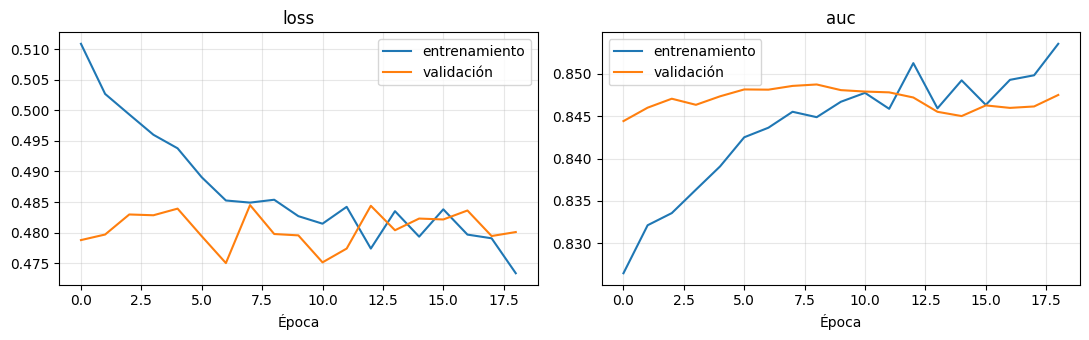

In [53]:
parada = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=10, restore_best_weights=True)
historia_churn = red_churn.fit(A_tr, y_tr, validation_data=(A_va, y_va), epochs=100, batch_size=64,
                               class_weight=pesos_clase, callbacks=[parada], verbose=1)
print("Épocas entrenadas:", len(historia_churn.history["loss"]), "(se detuvo sola)")
graficar(historia_churn, ("loss", "auc"))

**Qué deberías ver:** se detiene sola cerca de la época 25. La pérdida de entrenamiento sigue bajando, pero la de validación se estanca: desde ahí, la red empezaría a sobreajustar.

## Paso 2.5. Evaluar con prueba

In [54]:
prob_churn = red_churn.predict(A_te, verbose=0).ravel()
pred_churn = (prob_churn >= 0.5).astype(int)
print(f"ROC AUC en prueba: {roc_auc_score(y_te, prob_churn):.3f}")
print(classification_report(y_te, pred_churn, target_names=["Se queda", "Se va"], digits=3))

ROC AUC en prueba: 0.839
              precision    recall  f1-score   support

    Se queda      0.902     0.733     0.809      1035
       Se va      0.514     0.781     0.620       374

    accuracy                          0.746      1409
   macro avg      0.708     0.757     0.715      1409
weighted avg      0.799     0.746     0.759      1409



**Qué deberías ver:** un ROC AUC cercano a 0,84 y un recall de la clase "Se va" cercano a 0,78.

### Ejercicio 5
Guarda en `recall_red` el recall de la clase "Se va" con umbral 0,5, y en `n_contactar` cuántos clientes de prueba habría que contactar (los marcados como "Se va").

In [60]:
recall_red = recall_score(y_te, prob_churn >= 0.5)

n_contactar = int((prob_churn >= 0.5).sum())
print(recall_red, n_contactar)

0.7807486631016043 568


In [58]:
revisar(lambda: np.isclose(recall_red, recall_score(y_te, prob_churn >= 0.5)) and n_contactar == int((prob_churn >= 0.5).sum()))

Correcto.


### Ejercicio 6
Con la Clase 7 en mente: busca el umbral, entre `0.30` y `0.80` en pasos de `0.05`, que **maximiza el F1** de la clase "Se va". Guárdalo en `umbral_f1` (redondeado a 2 decimales).

In [63]:
umbrales = np.round(np.arange(0.30, 0.81, 0.05), 2)
umbral_f1 = [f1_score(y_te, prob_churn >= u) for u in umbrales]
umbral_f1 = umbrales[int(np.argmax(_f))]
print(umbral_f1)

0.55


In [64]:
_f = [f1_score(y_te, prob_churn >= u) for u in umbrales]
revisar(lambda: np.isclose(umbral_f1, umbrales[int(np.argmax(_f))]))

Correcto.


## Paso 2.6. ¿Le ganó la red a la regresión logística?

### Ejercicio 7
Entrena una `LogisticRegression(max_iter=3000, class_weight="balanced")` con **entrenamiento más validación** (`np.vstack` y `np.concatenate`), calcula su ROC AUC en prueba y guárdalo en `auc_logistica`. Luego guarda en `gana` el texto `"red"` o `"logistica"`, según cuál tenga mayor AUC.

In [68]:
from sklearn.linear_model import LogisticRegression

rl = LogisticRegression(max_iter=3000, class_weight="balanced").fit(np.vstack([A_tr, A_va]), np.concatenate([y_tr, y_va]))

auc_logistica = roc_auc_score(y_te, rl.fit(np.vstack([A_tr, A_va]), np.concatenate([y_tr, y_va])).predict_proba(A_te)[:, 1])
gana = "red" if roc_auc_score(y_te, prob_churn) > auc_logistica else "logistica"
print(auc_logistica, gana)

0.8415872277764861 logistica


In [69]:
_lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(np.vstack([A_tr, A_va]), np.concatenate([y_tr, y_va]))
_auc = roc_auc_score(y_te, _lr.predict_proba(A_te)[:, 1])
revisar(lambda: np.isclose(auc_logistica, _auc, atol=1e-3) and gana == ("red" if roc_auc_score(y_te, prob_churn) > _auc else "logistica"))

Correcto.


In [70]:
auc_logistica

np.float64(0.8415872277764861)

In [71]:
roc_auc_score(y_te, prob_churn)

np.float64(0.8392518535741043)

**Qué deberías ver:** resultados casi idénticos (cerca de 0,84 los dos), y probablemente la logística un poco arriba.

**Esta es la lección central de la parte.** En **datos en tabla** con pocas columnas, una red neuronal rara vez supera a un buen modelo clásico, y cuesta más entrenarla y explicarla. Las redes brillan con **imágenes, texto y sonido**, donde los modelos clásicos no tienen cómo ver la estructura (Parte 5). Para el capstone: si sus datos son una tabla, prueben primero scikit-learn.

---
# Parte 3. Caso: precio de diamantes (regresión)

En la Clase 4 clasificamos diamantes en gamas. Ahora predecimos el **precio exacto**. Usamos la misma muestra de 10.000 diamantes.

## Paso 3.1. Un truco para precios: el logaritmo

Los precios van de 300 a casi 19.000 dólares y están muy cargados hacia los valores bajos. Si la red predice el precio directo, los diamantes caros dominan el error. Predecir el **logaritmo del precio** pone todo en una escala parecida, y después se vuelve a dólares con `np.exp`.

In [ ]:
dm = sns.load_dataset("diamonds").sample(10_000, random_state=42).reset_index(drop=True)
for c in ["cut", "color", "clarity"]:
    dm[c] = dm[c].astype(str)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].hist(dm["price"], bins=50, color="#1428A0"); ejes[0].set_title("Precio (USD)")
ejes[1].hist(np.log(dm["price"]), bins=50, color="#FF6B35"); ejes[1].set_title("Logaritmo del precio")
plt.show()

F_D = ["carat", "cut", "color", "clarity", "depth", "table"]
ORDENES = [["Fair", "Good", "Very Good", "Premium", "Ideal"], ["J", "I", "H", "G", "F", "E", "D"],
           ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]]
prep_d = ColumnTransformer([("num", "passthrough", ["carat", "depth", "table"]),
                            ("cat", OrdinalEncoder(categories=ORDENES), ["cut", "color", "clarity"])])

Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(dm[F_D], np.log(dm["price"].values), test_size=0.2, random_state=42)
esc_d = StandardScaler().fit(prep_d.fit_transform(Xd_tr))
D_tr, D_te = esc_d.transform(prep_d.transform(Xd_tr)), esc_d.transform(prep_d.transform(Xd_te))
precio_real = np.exp(yd_te)
print("Entrenamiento:", D_tr.shape, "| Prueba:", D_te.shape)

**Qué deberías ver:** el histograma del precio muy cargado a la izquierda, y el del logaritmo mucho más parejo.

### Ejercicio 8
Construye, compila y entrena `red_precio`:

- Entrada de 6 columnas, `Dense(64)` y `Dense(32)` con `relu`, y la salida de **regresión**.
- Compilar con `adam`, pérdida `"mse"` y métrica `"mae"`.
- Entrenar con `validation_split=0.2`, hasta 200 épocas, `batch_size=64` y `EarlyStopping(patience=10, restore_best_weights=True)`.

Después, calcula `mae_red` en **dólares**: predice sobre `D_te`, vuelve a dólares con `np.exp` y compara con `precio_real`.

In [ ]:
keras.utils.set_random_seed(42)
red_precio = None  # TU CÓDIGO AQUÍ (definir, compilar y entrenar)

mae_red = None     # TU CÓDIGO AQUÍ
print(mae_red)

In [ ]:
revisar(lambda: red_precio.layers[-1].units == 1 and np.isclose(mae_red, mean_absolute_error(precio_real, np.exp(red_precio.predict(D_te, verbose=0).ravel()))) and mae_red < 600)

**Qué deberías ver:** un error medio cercano a **350 dólares**.

## Paso 3.2. Comparar

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

comparacion_precio = {
    "Regresión lineal": mean_absolute_error(precio_real, np.exp(LinearRegression().fit(D_tr, yd_tr).predict(D_te))),
    "Random forest": mean_absolute_error(precio_real, np.exp(RandomForestRegressor(200, random_state=42, n_jobs=-1).fit(D_tr, yd_tr).predict(D_te))),
    "Red neuronal": mae_red,
}
pd.Series(comparacion_precio, name="MAE (USD)").round(0)

**Qué deberías ver:** la regresión lineal con un error cercano a 1.600 dólares, y la red y el random forest cerca de 300 a 350. La relación entre las características y el precio **no es lineal**, y tanto la red (con sus capas ocultas) como el random forest la capturan. De nuevo, la red empata con un buen modelo clásico.

### Ejercicio 9
Usa `red_precio` para estimar el precio, **en dólares**, de un diamante de 1,0 quilates, corte `"Ideal"`, color `"G"`, pureza `"VS1"`, profundidad 61,5 y tabla 56. Guárdalo en `precio_estimado`. Pista: arma un DataFrame de una fila con las columnas de `F_D` y pásalo por `prep_d` y `esc_d`, en ese orden.

In [ ]:
precio_estimado = None  # TU CÓDIGO AQUÍ
print(precio_estimado)

In [ ]:
_d = pd.DataFrame([{"carat": 1.0, "cut": "Ideal", "color": "G", "clarity": "VS1", "depth": 61.5, "table": 56}])[F_D]
revisar(lambda: np.isclose(precio_estimado, float(np.exp(red_precio.predict(esc_d.transform(prep_d.transform(_d)), verbose=0)[0, 0])), rtol=1e-4))

---
# Parte 4. Caso: gama de precio (multiclase)

El mismo problema de la Clase 4: económica, media o premium, cada una con un tercio de los diamantes. Allá, el random forest llegó a cerca de 95% de exactitud.

In [ ]:
gama = pd.qcut(dm["price"], q=3, labels=[0, 1, 2]).astype(int).values      # 0 económica, 1 media, 2 premium
NOMBRES_GAMA = ["Económica", "Media", "Premium"]

Xg_tr, Xg_te, g_tr, g_te = train_test_split(dm[F_D], gama, test_size=0.2, random_state=42, stratify=gama)
esc_g = StandardScaler().fit(prep_d.fit_transform(Xg_tr))
G_tr, G_te = esc_g.transform(prep_d.transform(Xg_tr)), esc_g.transform(prep_d.transform(Xg_te))
print("Clases:", np.bincount(g_tr))

### Ejercicio 10
Construye, compila y entrena `red_gama`, igual que `red_precio` pero para **3 clases** con etiquetas **enteras**: elige la última capa y la pérdida correctas (Paso 1.1), con la métrica `"accuracy"`. Luego guarda en `exac_red_gama` la exactitud en prueba. Pista: la clase predicha es `argmax` de las probabilidades.

In [ ]:
keras.utils.set_random_seed(42)
red_gama = None        # TU CÓDIGO AQUÍ
exac_red_gama = None   # TU CÓDIGO AQUÍ
print(exac_red_gama)

In [ ]:
revisar(lambda: red_gama.layers[-1].units == 3 and red_gama.loss == "sparse_categorical_crossentropy"
        and np.isclose(exac_red_gama, accuracy_score(g_te, red_gama.predict(G_te, verbose=0).argmax(axis=1))) and exac_red_gama > 0.9)

**Qué deberías ver:** cerca de 0,95, igual que el random forest de la Clase 4.

### Ejercicio 11
Con la matriz de confusión de `red_gama`, ¿cuántos diamantes **económicos** confundió con **premium**? Guárdalo en `economica_como_premium`. Pista: `confusion_matrix(real, predicho)[fila, columna]`, donde la fila es la clase real.

In [ ]:
economica_como_premium = None  # TU CÓDIGO AQUÍ
print(economica_como_premium)

In [ ]:
revisar(lambda: economica_como_premium == confusion_matrix(g_te, red_gama.predict(G_te, verbose=0).argmax(axis=1))[0, 2])

**Qué deberías ver:** **0** o casi 0. Como en la Clase 4, los errores ocurren entre gamas vecinas, nunca entre los extremos.

---
# Parte 5. Caso: prendas de ropa con una red convolucional (láminas 191 a 212)

Aquí es donde las redes neuronales **sí** sacan ventaja. **Fashion-MNIST** tiene 70.000 imágenes de 28 × 28 pixeles de 10 tipos de prendas. Es más difícil que los dígitos de MNIST de la lámina 192.

## Paso 5.1. Cómo funciona una CNN

| Capa | Qué hace |
|---|---|
| `Conv2D(filtros, (3, 3))` | Desliza filtros de 3 × 3 por la imagen; cada filtro aprende a detectar un rasgo (bordes, texturas) |
| `MaxPooling2D((2, 2))` | Reduce la imagen a la mitad quedándose con el máximo de cada bloque de 2 × 2 |
| `Flatten()` | Convierte la imagen resultante en un vector |
| `Dense` | Combina los rasgos para decidir la clase |

**Parámetros de una `Conv2D`:** filtros × (alto × ancho × canales de entrada + 1). Por ejemplo, 32 filtros de 3 × 3 sobre una imagen de 1 canal: 32 × (9 + 1) = 320.

In [ ]:
(Xf_tr, yf_tr), (Xf_te, yf_te) = keras.datasets.fashion_mnist.load_data()
PRENDAS = ["Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo", "Sandalia", "Camisa", "Zapatilla", "Bolso", "Botín"]

fig, ejes = plt.subplots(1, 10, figsize=(13, 1.8))
for ax, k in zip(ejes, range(10)):
    i = np.where(yf_tr == k)[0][0]
    ax.imshow(Xf_tr[i], cmap="gray_r"); ax.set_title(PRENDAS[k], fontsize=8); ax.axis("off")
plt.show()

Xf_tr = (Xf_tr / 255.0).reshape(-1, 28, 28, 1).astype("float32")
Xf_te = (Xf_te / 255.0).reshape(-1, 28, 28, 1).astype("float32")
print("Entrenamiento:", Xf_tr.shape, "| Prueba:", Xf_te.shape)

**Qué deberías ver:** un ejemplo de cada prenda, y las formas (60000, 28, 28, 1) y (10000, 28, 28, 1): escaladas de 0 a 1 y con el canal agregado.

## Paso 5.2. Primero, una red densa (sin convolución)

Para comparar: una red que aplana la imagen y la trata como 784 columnas sueltas.

In [ ]:
keras.utils.set_random_seed(42)
densa_img = keras.Sequential([layers.Input(shape=(28, 28, 1)), layers.Flatten(),
                              layers.Dense(128, activation="relu"), layers.Dense(10, activation="softmax")])
densa_img.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
densa_img.fit(Xf_tr, yf_tr, epochs=5, batch_size=128, validation_split=0.1, verbose=0)
exac_densa = densa_img.evaluate(Xf_te, yf_te, verbose=0)[1]
print(f"Red densa: exactitud en prueba {exac_densa:.3f}")

**Qué deberías ver:** cerca de 0,87.

### Ejercicio 12
Construye `cnn_ropa` con esta arquitectura, compílala como la red densa y entrénala con los mismos parámetros (5 épocas, lotes de 128, 10% de validación). Guarda la exactitud en prueba en `exac_cnn`.

`Input(28, 28, 1)` → `Conv2D(32, (3, 3), relu)` → `MaxPooling2D((2, 2))` → `Conv2D(64, (3, 3), relu)` → `MaxPooling2D((2, 2))` → `Flatten()` → `Dropout(0.3)` → `Dense(10, softmax)`

In [ ]:
keras.utils.set_random_seed(42)
cnn_ropa = None   # TU CÓDIGO AQUÍ
exac_cnn = None   # TU CÓDIGO AQUÍ
print(exac_cnn)

In [ ]:
revisar(lambda: cnn_ropa.count_params() == 34826 and np.isclose(exac_cnn, cnn_ropa.evaluate(Xf_te, yf_te, verbose=0)[1]))

**Qué deberías ver:** cerca de **0,90 o 0,91**, mejor que la red densa con **menos parámetros** (34.826 contra más de 100.000). La convolución aprovecha que los pixeles cercanos están relacionados.

### Ejercicio 13
¿Qué par de prendas confunde más `cnn_ropa`? Calcula la matriz de confusión, ignora la diagonal (los aciertos) y encuentra la celda más grande. Guarda en `par_confundido` una tupla `(prenda_real, prenda_predicha)` con los **nombres** de `PRENDAS`.

In [ ]:
par_confundido = None  # TU CÓDIGO AQUÍ
print(par_confundido)

In [ ]:
_cm = confusion_matrix(yf_te, cnn_ropa.predict(Xf_te, verbose=0).argmax(axis=1)); np.fill_diagonal(_cm, 0)
_i, _j = np.unravel_index(_cm.argmax(), _cm.shape)
revisar(lambda: tuple(par_confundido) == (PRENDAS[_i], PRENDAS[_j]))

**Qué deberías ver:** casi siempre **camisa con camiseta** (o con suéter o abrigo). Tiene sentido: a 28 × 28 pixeles, son prendas muy parecidas incluso para una persona.

---
# Parte 6. Caso: pasajeros de avión con redes recurrentes (láminas 213 a 230)

## Paso 6.1. ¿Qué es una red recurrente?

Las redes de las Partes 2 a 5 reciben **todo de una vez**. Una **red recurrente (RNN)** recibe una **secuencia** y la lee **paso a paso**, guardando una memoria (el estado oculto $h$) que se actualiza en cada paso:

$$h_t = \\tanh(W \\cdot x_t + U \\cdot h_{t-1} + b)$$

Es decir: la memoria nueva combina el dato actual $x_t$ con la memoria anterior $h_{t-1}$. Al terminar la secuencia, $h$ resume todo lo visto.

**El problema:** en secuencias largas, la RNN simple olvida lo del principio (el gradiente que desaparece de la Clase 14).

**Las soluciones:**

- **LSTM:** agrega una "cinta" de memoria con tres puertas (olvido, entrada y salida) que deciden qué borrar, qué guardar y qué mostrar (lámina 214).
- **GRU:** una versión simplificada de la LSTM, con dos puertas. Tiene menos parámetros y suele rendir parecido.

| Capa de Keras | Puertas | Parámetros (con 32 neuronas y 1 entrada) |
|---|---|---|
| `SimpleRNN(32)` | Ninguna | 32 × (32 + 1 + 1) = 1.088 |
| `GRU(32)` | 2 | Cerca de 3 veces la RNN |
| `LSTM(32)` | 3 | 4 veces la RNN: 4.352 |

## Paso 6.2. Los datos y las ventanas

144 meses de pasajeros (miles), con tendencia y estacionalidad. Entrenamos con los primeros 120 meses y probamos con los últimos 24. Cada ejemplo: 12 meses → el mes siguiente.

Entrenamiento: (108, 12, 1) (ejemplos, pasos de tiempo, características) | Prueba: (24, 12, 1)


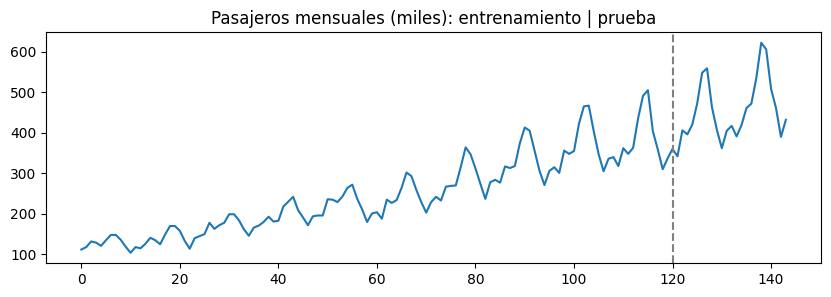

In [4]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

serie = sns.load_dataset("flights")["passengers"].values.astype("float32")
ENTRENO, VENTANA = 120, 12

esc_s = MinMaxScaler().fit(serie[:ENTRENO].reshape(-1, 1))
serie_e = esc_s.transform(serie.reshape(-1, 1)).ravel()

def ventanas(datos, largo):
    X, y = [], []
    for i in range(len(datos) - largo):
        X.append(datos[i:i + largo]); y.append(datos[i + largo])
    return np.array(X).reshape(-1, largo, 1), np.array(y)

S_tr, s_tr = ventanas(serie_e[:ENTRENO], VENTANA)
S_te, s_te = ventanas(serie_e[ENTRENO - VENTANA:], VENTANA)
print("Entrenamiento:", S_tr.shape, "(ejemplos, pasos de tiempo, características) | Prueba:", S_te.shape)

plt.figure(figsize=(10, 3)); plt.plot(serie); plt.axvline(ENTRENO, ls="--", color="gray")
plt.title("Pasajeros mensuales (miles): entrenamiento | prueba"); plt.show()

### Ejercicio 14
Comprueba la tabla del Paso 6.1: construye un modelo con `Input(shape=(12, 1))` y `SimpleRNN(32)`, y guarda en `params_rnn` los parámetros de la capa `SimpleRNN` (con `modelo.layers[0].count_params()`).

In [7]:
import keras
from keras import layers


modelo_rnn = keras.Sequential([
    layers.Input(shape=(12, 1)),     # 12 pasos de tiempo, 1 característica por paso
    layers.SimpleRNN(32),
    layers.Dense(1),
])

params_rnn = modelo_rnn.layers[0].count_params()
print(params_rnn)

1088


In [11]:
revisar(lambda: params_rnn == 32 * (32 + 1 + 1))

Correcto.


## Paso 6.3. Comparar RNN, LSTM y GRU

### Ejercicio 15
Completa `red_serie(capa)` para que arme, compile (`adam`, `mse`) y entrene (200 épocas, lotes de 16, `verbose=0`) un modelo con `Input(shape=(VENTANA, 1))`, la capa recibida y `Dense(1)`. Luego se entrenan las tres variantes y se comparan con la **línea base ingenua estacional** (repetir el mismo mes del año anterior).

{'Ingenua estacional': 50.0, 'RNN': 295.4, 'LSTM': 321.8, 'GRU': 311.5}


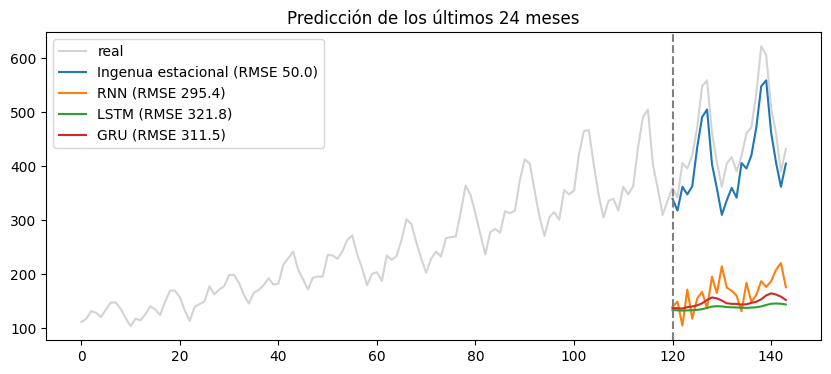

In [12]:
def red_serie(capa):
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([
        layers.Input(shape=(VENTANA, 1)),              # cada ejemplo: 12 meses, 1 valor por mes
        capa,                                          # la capa recurrente que recibe la función
        layers.Dense(1),                               # salida: 1 número (regresión, sin activación)
    ])
    return modelo

real_s = serie[ENTRENO:]
predicciones_s = {"Ingenua estacional": serie[ENTRENO - 12:-12]}
for nombre, capa in [("RNN", layers.SimpleRNN(32)), ("LSTM", layers.LSTM(32)), ("GRU", layers.GRU(32))]:
    modelo = red_serie(capa)
    if modelo is not None:
        predicciones_s[nombre] = esc_s.inverse_transform(modelo.predict(S_te, verbose=0)).ravel()

rmse_s = {n: float(np.sqrt(mean_squared_error(real_s, p))) for n, p in predicciones_s.items()}
print({n: round(v, 1) for n, v in rmse_s.items()})

plt.figure(figsize=(10, 4))
plt.plot(range(len(serie)), serie, color="lightgray", label="real")
for n, p in predicciones_s.items():
    plt.plot(range(ENTRENO, len(serie)), p, label=f"{n} (RMSE {rmse_s[n]:.1f})")
plt.axvline(ENTRENO, ls="--", color="gray"); plt.legend(); plt.title("Predicción de los últimos 24 meses"); plt.show()

In [13]:
revisar(lambda: set(rmse_s) == {"Ingenua estacional", "RNN", "LSTM", "GRU"})

Correcto.


**Qué deberías ver:** cuatro RMSE en miles de pasajeros. En nuestras pruebas, la línea base estuvo cerca de 50, y las redes entre 40 y 70 según el tipo; los números pueden variar un poco entre computadores.

**Lean la comparación con cuidado:** con solo 108 ventanas, **no siempre gana la red más compleja**, y a veces la línea base es muy difícil de superar. Las redes además predicen mal valores más altos que todos los que vieron en el entrenamiento (la tendencia sigue subiendo en la prueba).

### Ejercicio 16
Guarda en `mejor_serie` el nombre del modelo con menor RMSE, y en `supera_base` un booleano que diga si **alguna** red le ganó a la línea base.

In [14]:
rmse_s

{'Ingenua estacional': 49.98666570243383,
 'RNN': 295.41328306712956,
 'LSTM': 321.8098599134278,
 'GRU': 311.5205776710425}

In [16]:
rmse_s.get

<function dict.get(key, default=None, /)>

In [17]:
min(rmse_s)

'GRU'

In [22]:
rmse_s.get("Ingenua estacional") < rmse_s["RNN"]

True

In [23]:
rmse_s.get("Ingenua estacional") < rmse_s["LSTM"]

True

In [24]:
rmse_s.get("Ingenua estacional") < rmse_s["GRU"]

True

In [25]:
rmse_s.get("Ingenua estacional") < rmse_s["GRU"] or rmse_s.get("Ingenua estacional") < rmse_s["LSTM"] or rmse_s.get("Ingenua estacional") < rmse_s["RNN"]

True

In [34]:
mejor_serie = min(rmse_s, key=rmse_s.get)
supera_base = any(v < rmse_s["Ingenua estacional"] for n, v in rmse_s.items() if n != "Ingenua estacional")
print(mejor_serie, supera_base)

Ingenua estacional False


In [35]:
revisar(lambda: mejor_serie == min(rmse_s, key=rmse_s.get) and supera_base == any(v < rmse_s["Ingenua estacional"] for n, v in rmse_s.items() if n != "Ingenua estacional"))

Correcto.


---
# Parte 7. Desafío para la casa: superar el AUC de la fuga de clientes

En la Parte 2, la red y la logística quedaron cerca de 0,84 de ROC AUC. **El desafío: superar 0,85 en el conjunto de prueba**, sin tocar `A_te` ni `y_te` para entrenar.

Ideas para probar, de a una y midiendo con validación:

1. **Variables nuevas:** cargo total dividido por antigüedad, número de servicios contratados, contrato mes a mes con fibra (el segmento de la Clase 8).
2. **Arquitectura:** más o menos neuronas, más capas, más dropout, `BatchNormalization`.
3. **Entrenamiento:** tasa de aprendizaje de Adam (`keras.optimizers.Adam(learning_rate=...)`), tamaño de lote, paciencia.
4. **Otros modelos:** `GradientBoostingClassifier` o XGBoost (Clase 3), y comparar.

Registren en una tabla cada intento: qué cambiaron, AUC de validación y AUC de prueba al final. **Si nada supera claramente a la logística, esa también es una conclusión válida** para su informe: es justo lo que pasa en muchos problemas reales con datos en tabla.

In [72]:
# ver el AUC de la red
print(roc_auc_score(y_te, red_churn.predict(A_te, verbose=0)))

0.8392518535741043


In [73]:
auc_logistica

np.float64(0.8415872277764861)

In [74]:
# RandomForestClassifier para el conjunto de datos
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(A_tr, y_tr)
print(roc_auc_score(y_te, rf.predict_proba(A_te)[:, 1]))

0.8244335942545662


In [75]:
# Busqueda de hiperparametros para el rf
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

grid_search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), param_grid, cv=5, scoring="roc_auc", n_jobs=-1, verbose=1)
grid_search.fit(A_tr, y_tr)
print(grid_search.best_params_)
print(grid_search.best_score_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
{'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
0.8457156564504515


In [76]:
# Nuevo RF con los mejores hiperparámetros
rf = RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_split=5, min_samples_leaf=1, random_state=42, n_jobs=-1)
rf.fit(A_tr, y_tr)
print(roc_auc_score(y_te, rf.predict_proba(A_te)[:, 1]))

0.8304967836937147


In [77]:
# Ahora quiero probar GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(A_tr, y_tr)
print(roc_auc_score(y_te, gb.predict_proba(A_te)[:, 1]))

0.8408109225244774


In [78]:
# Buscar hiperparametros para GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.1, 1],
    "max_depth": [1, 2, 3, 4],
}

grid_search = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=5, scoring="roc_auc", n_jobs=-1, verbose=1)
grid_search.fit(A_tr, y_tr)
print(grid_search.best_params_)
print(grid_search.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
{'learning_rate': 0.1, 'max_depth': 1, 'n_estimators': 200}
0.8484616800984082


In [80]:
# Probar GradientBoostingClassifier con mejores hiperparámetros
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=1, random_state=42)
gb.fit(A_tr, y_tr)
print(roc_auc_score(y_te, gb.predict_proba(A_te)[:, 1]))

0.8464491461933917


In [86]:
# Probar búsqueda de hiperparámetros para GradientBoostingClassifier con RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [50, 100, 200, 250, 300],
    "learning_rate": [0.01, 0.1, 1],
    "max_depth": [1, 2, 3, 4],
    "validation_fraction": [0.1, 0.2, 0.3],
    "n_iter_no_change": [5, 10, 15],
    "tol": [1e-3, 1e-4, 1e-5],
}

random_search = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), param_dist, cv=5, scoring="roc_auc", n_jobs=-1, verbose=1, n_iter=10)
random_search.fit(A_tr, y_tr)
print(random_search.best_params_)
print(random_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
{'validation_fraction': 0.1, 'tol': 0.0001, 'n_iter_no_change': 15, 'n_estimators': 250, 'max_depth': 1, 'learning_rate': 0.1}
0.8479683367047818


In [89]:
# Probar GradientBoostingClassifier con mejores hiperparámetros {'validation_fraction': 0.2, 'tol': 0.0001, 'n_iter_no_change': 10, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.01, 'ccp_alpha': 0.1}

gb = GradientBoostingClassifier(validation_fraction= 0.1, tol= 0.0001, n_iter_no_change= 15, n_estimators= 250, max_depth= 1, learning_rate= 0.1)
gb.fit(A_tr, y_tr)
print(roc_auc_score(y_te, gb.predict_proba(A_te)[:, 1]))

0.8468624867601849


In [116]:
# Vamos a probar con una neurona secuencial
from keras.models import Sequential
from keras.layers import Dense


def construir_red_churn():
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([
        keras.layers.Input(shape=(A_tr.shape[1],)),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(8, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid")
    ])
    modelo.compile(
        optimizer="SGD",
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")]
    )

    return modelo

red_churn = construir_red_churn()
red_churn.summary() if red_churn is not None else None

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_40 (Dense)                │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,177 (8.50 KB)

 Trainable params: 2,177 (8.50 KB)

 Non-trainable params: 0 (0.00 B)

Épocas entrenadas: 73 (se detuvo sola)


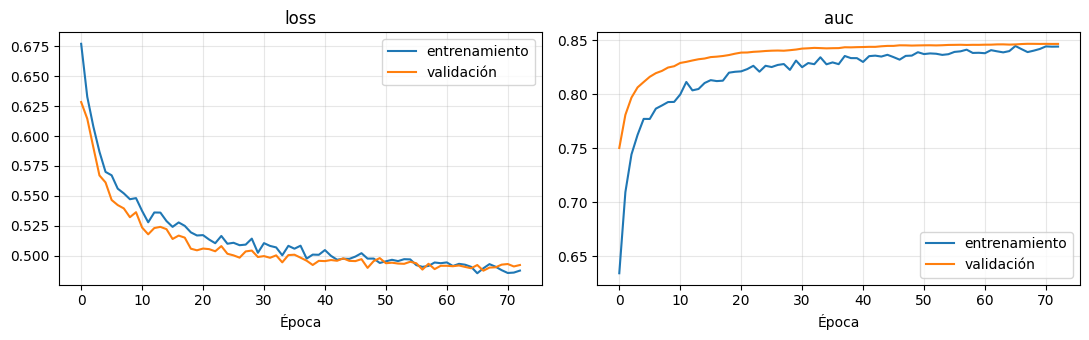

In [117]:
parada = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True)
historia_churn = red_churn.fit(A_tr, y_tr, validation_data=(A_va, y_va), epochs=100, batch_size=64,
                               class_weight=pesos_clase, callbacks=[parada], verbose=0)
print("Épocas entrenadas:", len(historia_churn.history["loss"]), "(se detuvo sola)")
graficar(historia_churn, ("loss", "auc"))

Épocas entrenadas: 46 (se detuvo sola)


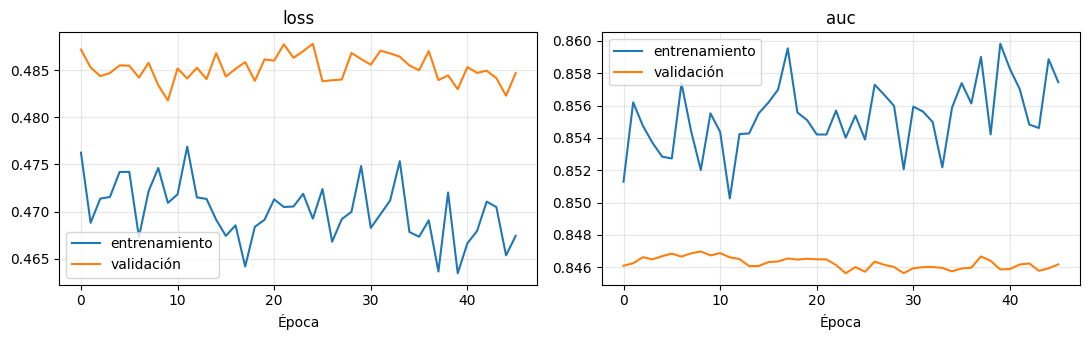

In [124]:
historia_churn = red_churn.fit(A_tr, y_tr, validation_data=(A_va, y_va), epochs=46, batch_size=64,
                               class_weight=pesos_clase, verbose=0)
print("Épocas entrenadas:", len(historia_churn.history["loss"]), "(se detuvo sola)")
graficar(historia_churn, ("loss", "auc"))

In [125]:
prob_churn = red_churn.predict(A_te, verbose=0).ravel()
pred_churn = (prob_churn >= 0.5).astype(int)
print(f"ROC AUC en prueba: {roc_auc_score(y_te, prob_churn):.3f}")

ROC AUC en prueba: 0.843


---
# Cierre

| Caso | Mejor resultado | Conclusión |
|---|---|---|
| Fuga de clientes | Red y logística empatadas (AUC cerca de 0,84) | En tablas, probar primero modelos clásicos |
| Precio de diamantes | Red y random forest (MAE cerca de 300 a 350 USD), lineal muy atrás | Las capas ocultas capturan relaciones no lineales |
| Gama de precio | Red y random forest (cerca de 0,95) | Empate |
| Prendas de ropa | CNN (cerca de 0,91) sobre red densa (0,87) | Con imágenes, la convolución sí marca la diferencia |
| Pasajeros | Depende: la línea base es difícil de superar | Con pocos datos, comparar siempre con algo simple |

Guarden el notebook en `ejercicios_estudiantes` como `clase15_su_nombre.ipynb`.

---
# Soluciones

### Ejercicio 1
46 entradas × 32 neuronas + 32 sesgos = 1.504.

In [ ]:
params_capa1 = 46 * 32 + 32
print(params_capa1)

### Ejercicio 2
1.504 + (32 × 16 + 16) + (16 × 1 + 1) = 1.504 + 528 + 17 = 2.049. El Dropout no suma parámetros.

In [ ]:
params_total = (46 * 32 + 32) + (32 * 16 + 16) + (16 * 1 + 1)
_m = keras.Sequential([layers.Input(shape=(46,)), layers.Dense(32), layers.Dropout(0.3), layers.Dense(16), layers.Dense(1)])
print(params_total, _m.count_params())

### Ejercicio 3

In [ ]:
pesos_clase = {0: float(len(y_tr) / (2 * (y_tr == 0).sum())), 1: float(len(y_tr) / (2 * (y_tr == 1).sum()))}
print(pesos_clase)

### Ejercicio 4

In [ ]:
def construir_red_churn():
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([
        layers.Input(shape=(A_tr.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    modelo.compile(optimizer="adam", loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")])
    return modelo

red_churn = construir_red_churn()
parada = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=10, restore_best_weights=True)
red_churn.fit(A_tr, y_tr, validation_data=(A_va, y_va), epochs=100, batch_size=64,
              class_weight=pesos_clase, callbacks=[parada], verbose=0)
prob_churn = red_churn.predict(A_te, verbose=0).ravel()
print(red_churn.count_params(), round(roc_auc_score(y_te, prob_churn), 3))

### Ejercicio 5

In [ ]:
recall_red = recall_score(y_te, prob_churn >= 0.5)
n_contactar = int((prob_churn >= 0.5).sum())
print(round(recall_red, 3), n_contactar)

### Ejercicio 6

In [ ]:
umbrales = np.round(np.arange(0.30, 0.81, 0.05), 2)
f1s = [f1_score(y_te, prob_churn >= u) for u in umbrales]
umbral_f1 = float(umbrales[int(np.argmax(f1s))])
print(umbral_f1, round(max(f1s), 3))

### Ejercicio 7

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(np.vstack([A_tr, A_va]), np.concatenate([y_tr, y_va]))
auc_logistica = roc_auc_score(y_te, lr.predict_proba(A_te)[:, 1])
gana = "red" if roc_auc_score(y_te, prob_churn) > auc_logistica else "logistica"
print(round(auc_logistica, 3), gana)

### Ejercicio 8

In [ ]:
keras.utils.set_random_seed(42)
red_precio = keras.Sequential([
    layers.Input(shape=(6,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),                                  # regresión: sin activación
])
red_precio.compile(optimizer="adam", loss="mse", metrics=["mae"])
red_precio.fit(D_tr, yd_tr, validation_split=0.2, epochs=200, batch_size=64,
               callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)], verbose=0)
mae_red = mean_absolute_error(precio_real, np.exp(red_precio.predict(D_te, verbose=0).ravel()))
print(round(mae_red, 1))

### Ejercicio 9
El DataFrame tiene que tener las columnas en el mismo orden que `F_D`, y pasar por los mismos dos transformadores que el entrenamiento.

In [ ]:
nuevo = pd.DataFrame([{"carat": 1.0, "cut": "Ideal", "color": "G", "clarity": "VS1", "depth": 61.5, "table": 56}])[F_D]
precio_estimado = float(np.exp(red_precio.predict(esc_d.transform(prep_d.transform(nuevo)), verbose=0)[0, 0]))
print(round(precio_estimado))

### Ejercicio 10
Para 3 clases con etiquetas enteras: `Dense(3, activation="softmax")` y `sparse_categorical_crossentropy`.

In [ ]:
keras.utils.set_random_seed(42)
red_gama = keras.Sequential([
    layers.Input(shape=(6,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(3, activation="softmax"),
])
red_gama.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
red_gama.fit(G_tr, g_tr, validation_split=0.2, epochs=200, batch_size=64,
             callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)], verbose=0)
exac_red_gama = accuracy_score(g_te, red_gama.predict(G_te, verbose=0).argmax(axis=1))
print(round(exac_red_gama, 3))

### Ejercicio 11
Fila 0 (real: económica), columna 2 (predicha: premium).

In [ ]:
economica_como_premium = confusion_matrix(g_te, red_gama.predict(G_te, verbose=0).argmax(axis=1))[0, 2]
print(economica_como_premium)

### Ejercicio 12
Parámetros: 320 (primera Conv2D) + 18.496 (segunda) + 16.010 (Dense: 5 × 5 × 64 = 1.600 entradas × 10 + 10) = 34.826.

In [ ]:
keras.utils.set_random_seed(42)
cnn_ropa = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])
cnn_ropa.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_ropa.fit(Xf_tr, yf_tr, epochs=5, batch_size=128, validation_split=0.1, verbose=0)
exac_cnn = cnn_ropa.evaluate(Xf_te, yf_te, verbose=0)[1]
print(cnn_ropa.count_params(), round(exac_cnn, 3))

### Ejercicio 13
`np.fill_diagonal(cm, 0)` borra los aciertos; `np.unravel_index(cm.argmax(), cm.shape)` da la fila y la columna de la celda más grande.

In [ ]:
cm = confusion_matrix(yf_te, cnn_ropa.predict(Xf_te, verbose=0).argmax(axis=1))
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(cm.argmax(), cm.shape)
par_confundido = (PRENDAS[i], PRENDAS[j])
print(par_confundido, cm[i, j])

### Ejercicio 14
32 neuronas × (32 de la memoria anterior + 1 entrada + 1 sesgo) = 1.088.

In [ ]:
_m = keras.Sequential([layers.Input(shape=(12, 1)), layers.SimpleRNN(32), layers.Dense(1)])
params_rnn = _m.layers[0].count_params()
print(params_rnn)

### Ejercicio 15

In [ ]:
def red_serie(capa):
    keras.utils.set_random_seed(42)
    modelo = keras.Sequential([layers.Input(shape=(VENTANA, 1)), capa, layers.Dense(1)])
    modelo.compile(optimizer="adam", loss="mse")
    modelo.fit(S_tr, s_tr, epochs=200, batch_size=16, verbose=0)
    return modelo

real_s = serie[ENTRENO:]
predicciones_s = {"Ingenua estacional": serie[ENTRENO - 12:-12]}
for nombre, capa in [("RNN", layers.SimpleRNN(32)), ("LSTM", layers.LSTM(32)), ("GRU", layers.GRU(32))]:
    predicciones_s[nombre] = esc_s.inverse_transform(red_serie(capa).predict(S_te, verbose=0)).ravel()
rmse_s = {n: float(np.sqrt(mean_squared_error(real_s, p))) for n, p in predicciones_s.items()}
print({n: round(v, 1) for n, v in rmse_s.items()})

### Ejercicio 16

In [ ]:
mejor_serie = min(rmse_s, key=rmse_s.get)
supera_base = any(v < rmse_s["Ingenua estacional"] for n, v in rmse_s.items() if n != "Ingenua estacional")
print(mejor_serie, supera_base)